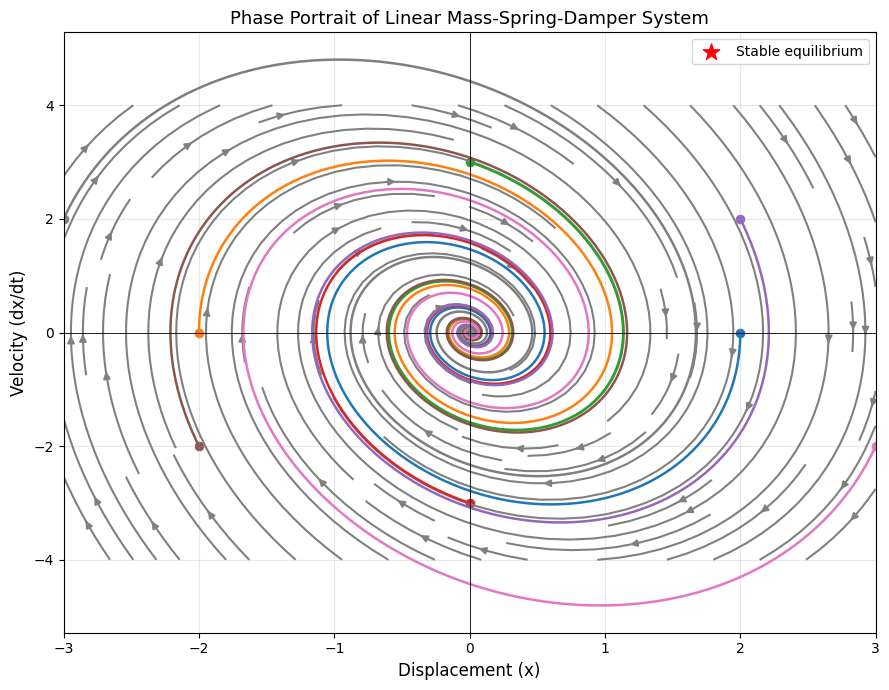

In [5]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
# Step 1: Define system parameters
m = 1.0
c = 0.8
k = 4.0
# Step 2: Define the state-space equations
def system(t, X):
    x, v = X

    dxdt = v
    dvdt = -(c/m)*v - (k/m)*x

    return [dxdt, dvdt]
# Step 3: Define simulation time
t_span = (0, 20)
t_eval = np.linspace(0, 20, 1500)
# Step 4: Specify different initial conditions
initial_conditions = [
    [2, 0], [-2, 0],
    [0, 3], [0, -3],
    [2, 2], [-2, -2],
    [3, -2], [-3, 2]
]
# Step 5: Construct the phase plane grid
x = np.linspace(-3, 3, 25)
v = np.linspace(-4, 4, 25)
X, V = np.meshgrid(x, v)
# Step 6: Calculate the vector field
U = V
W = -(c/m)*V - (k/m)*X
# Step 7: Plot the phase portrait
plt.figure(figsize=(9, 7))

plt.streamplot(
    X, V, U, W,
    color='gray',
    density=1.2,
    arrowsize=1
)
# Step 8: Solve the system for different initial conditions
for initial in initial_conditions:

    solution = solve_ivp(
        system,
        t_span,
        initial,
        t_eval=t_eval
    )

    plt.plot(
        solution.y[0],
        solution.y[1],
        linewidth=1.8
    )

    plt.scatter(
        initial[0],
        initial[1],
        s=35
    )

# Step 9: Mark the equilibrium point
plt.scatter(
    0, 0,
    color='red',
    marker='*',
    s=150,
    label='Stable equilibrium'
)
# Step 10: Add labels and formatting
plt.xlabel('Displacement (x)', fontsize=12)
plt.ylabel('Velocity (dx/dt)', fontsize=12)

plt.title(
    'Phase Portrait of Linear Mass-Spring-Damper System',
    fontsize=13
)
plt.axhline(0, color='black', linewidth=0.6)
plt.axvline(0, color='black', linewidth=0.6)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()